<a href="https://colab.research.google.com/github/zacw-243L/Oracle-Engine-to-estimate-Unifrom-amount/blob/main/Oracle%20Engine%20to%20estimate%20Unifrom%20amount.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Oracle Engine

## Part 1: Prepare the uniform data

This section prepares the uniform collection file for the forecasting system.
**Just click the ▶ Run button beside each step, from 1 to 4.** Wait for each step to finish before moving on.

**Before starting:** Place the sample CSV named **`PCG MPC Uniform Collection-XXXXXXXXXXXXXXXXXXXXXXXX.csv`** in **My Drive** on Google Drive.
You can leave the filename as it is.

**When finished:** Your prepared file will be saved automatically in Google Drive, inside the folder **OracleEngineSanitizedOutput**, as **Cleaned Data.csv**.

The folder will be created automatically if it does not already exist. Your original collection file will remain unchanged.



In [39]:

# @title 1. Connect Google Drive { display-mode: "form", single-column: true }
# @markdown Click **Run** to connect Google Drive and locate the collection file.

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

_drive_folder = Path('/content/drive/MyDrive')

_source_on_drive = (
    _drive_folder /
    'PCG MPC Uniform Collection-6ab61ef0a70268fced1f06aa.csv'
)

_local_folder = Path('/content/OracleEngineSanitizedOutput')
_local_folder.mkdir(parents=True, exist_ok=True)

if not _source_on_drive.is_file():
    raise FileNotFoundError(
        'Collection file not found in My Drive.'
    )

# Remove an old raw copy from earlier notebook versions.
_old_raw = _local_folder / 'raw_input.csv'
_old_raw.unlink(missing_ok=True)

print('Google Drive connected.')
print('Collection file located.')
print('Please run Step 2.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected.
Collection file located.
Please run Step 2.


In [40]:

# @title 2. Remove personal details { display-mode: "form", single-column: true }
# @markdown Click **Run** to prepare the uniform collection data.

import csv

_working_columns = [
    'Timestamp',
    'Intake',
    'No.4 Shirt (Size, Qty)',
    'No.4 Trousers (Size, Qty)',
    'PCG No.4 Utility Belt (Size, Qty)',
    'PCG No.4 Tactical Belt (Size, Qty)',
    'Fire & Cut Resistant Tactical Gloves (Size, Qty)',
    'Insignia: Deckhand (Qty)',
    'No.4 ERT Badge (Qty)',
    'Duffle Bag (Qty)',
    'Utility Bag (Qty)'
]

_working_path = _local_folder / 'working_data.csv'


def _sanitize_source():

    temp_path = _local_folder / 'working_data.tmp'
    temp_path.unlink(missing_ok=True)

    # Prevent reuse of an outdated working file.
    _working_path.unlink(missing_ok=True)

    count = 0
    excluded = 0

    try:
        with (
            _source_on_drive.open(
                'r', encoding='utf-8-sig', newline=''
            ) as source,
            temp_path.open(
                'w', encoding='utf-8-sig', newline=''
            ) as destination
        ):
            reader = csv.reader(source)

            # Locate the FormSG response header.
            for header_line, row in enumerate(reader, start=1):
                if {'Response ID', 'Timestamp', 'Intake'}.issubset(row):
                    columns = row
                    break
            else:
                raise ValueError('FormSG response header not found.')

            if len(columns) != len(set(columns)):
                raise ValueError('Duplicate source columns found.')

            missing = [
                c for c in _working_columns if c not in columns
            ]

            if missing:
                raise ValueError(
                    'Missing required columns: ' + ', '.join(missing)
                )

            writer = csv.DictWriter(
                destination, fieldnames=_working_columns
            )
            writer.writeheader()

            for line_number, values in enumerate(
                reader, start=header_line + 1
            ):
                if not any(v.strip() for v in values):
                    continue

                if len(values) != len(columns):
                    raise ValueError(
                        f'Invalid field count at row {line_number}.'
                    )

                response = dict(zip(columns, values))

                if response.get(
                    'Download Status', 'Success'
                ).strip().lower() != 'success':
                    excluded += 1
                    continue

                # Restrict this demonstration to fictional records.
                if not response.get(
                    'Name', ''
                ).strip().startswith('SYNTHETIC PERSON '):
                    raise ValueError(
                        'Only synthetic demonstration data is permitted.'
                    )

                # Allowlist: identifying columns never reach the output.
                cleaned = {
                    c: response[c].strip()
                    for c in _working_columns
                }

                if not cleaned['Timestamp'] or not cleaned['Intake']:
                    raise ValueError(
                        f'Missing date or intake at row {line_number}.'
                    )

                writer.writerow(cleaned)
                count += 1

        if count == 0:
            raise ValueError('No valid responses found.')

        temp_path.replace(_working_path)

        return count, excluded

    finally:
        temp_path.unlink(missing_ok=True)


_count, _excluded = _sanitize_source()

print(f'{_count:,} responses prepared.')
print(f'{_excluded:,} unsuccessful responses skipped.')
print('Identifying fields excluded.')
print('Please run Step 3.')


1,416 responses prepared.
0 unsuccessful responses skipped.
Identifying fields excluded.
Please run Step 3.


In [41]:
# @title 3. Clean and save the uniform data { display-mode: "form", single-column: true }
# @markdown Click **▶ Run** to prepare the final file. It will be saved to **My Drive** as **Cleaned Data.csv**. Running this step again replaces the previous Cleaned Data.csv.
import csv
import re
import shutil
from datetime import datetime
from pathlib import Path

if '_working_path' not in globals() or not _working_path.is_file():
    raise RuntimeError('Please run Step 2 first.')

# The final 9 columns match the forecasting example exactly.
_clean_columns = [
    'Timestamp', 'Intake',
    'No.4 Shirt (Size, Qty)', 'No.4 Trousers (Size, Qty)',
    'PCG No.4 Utility Belt (Size, Qty)',
    'PCG No.4 Tactical Belt (Size, Qty)',
    'Fire & Cut Resistant Tactical Gloves (Size, Qty)',
    'Insignia: Deckhand (Qty)', 'No.4 ERT Badge (Qty)'
]

with _working_path.open('r', encoding='utf-8-sig', newline='') as file:
    _reader = csv.DictReader(file)
    if not _reader.fieldnames or any(col not in _reader.fieldnames for col in _clean_columns):
        raise ValueError('The working data is missing required uniform fields. Run Step 2 again.')
    _clean_records = [{col: row[col] for col in _clean_columns} for row in _reader]

# Catch accidental changes to the FormSG table layout before exporting.
_patterns = {
    'No.4 Shirt (Size, Qty)': r'No\.4 Shirt size (?:[1-9]|10);\d+',
    'No.4 Trousers (Size, Qty)': r'No\.4 Trouser size (?:[1-9]|1[0-4]);\d+',
    'PCG No.4 Utility Belt (Size, Qty)': r'Utility Belt size (?:S|M|L|XL);\d+',
    'PCG No.4 Tactical Belt (Size, Qty)': r'Tactical Belt size (?:S|M|L|XL);\d+',
    'Fire & Cut Resistant Tactical Gloves (Size, Qty)': r'Fire & Cut Resistant Tactical Gloves Size (?:S|M|L|XL);\d+'
}
for _n, _record in enumerate(_clean_records, start=2):
    if not _record['Intake'].isdigit():
        raise ValueError(f'Invalid intake number at data row {_n}.')
    try:
        datetime.strptime(_record['Timestamp'], '%d/%m/%Y %H:%M')
    except ValueError:
        raise ValueError(f'Invalid timestamp at data row {_n}.') from None
    for _column, _pattern in _patterns.items():
        if not re.fullmatch(_pattern, _record[_column]):
            raise ValueError(f'Unrecognised uniform size or quantity at data row {_n}, column {_column}.')
    for _column in _clean_columns[7:]:
        if not _record[_column].isdigit():
            raise ValueError(f'Invalid item quantity at data row {_n}, column {_column}.')

# Write and verify locally before copying the completed file back to Drive.
_clean_local = _local_folder / 'Cleaned Data.csv'

with _clean_local.open('w', encoding='utf-8-sig', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=_clean_columns)
    writer.writeheader()
    writer.writerows(_clean_records)

# Create the output folder inside Google Drive.
_output_folder = _drive_folder / 'OracleEngineSanitizedOutput'
_output_folder.mkdir(parents=True, exist_ok=True)

# Save the cleaned CSV inside that folder.
_clean_drive = _output_folder / 'Cleaned Data.csv'
shutil.copyfile(_clean_local, _clean_drive)

print('Step 3 complete.')
print('Cleaned Data.csv saved successfully.')
print(f'{len(_clean_records):,} responses and 9 uniform-data columns are ready.')
print(f'Location: {_clean_drive}')
print('Please run Step 4 to check the results.')

# Remove temporary working files after successful export.
_working_path.unlink(missing_ok=True)
_clean_local.unlink(missing_ok=True)

# Clear temporary notebook variables left by earlier versions.
for variable in (
    '_raw_lines',
    '_raw_columns',
    '_working_records',
    '_response',
    '_values'
):
    globals().pop(variable, None)

print('Temporary working files removed.')
print('Cleaned Data.csv is ready.')

Step 3 complete.
Cleaned Data.csv saved successfully.
1,416 responses and 9 uniform-data columns are ready.
Location: /content/drive/MyDrive/OracleEngineSanitizedOutput/Cleaned Data.csv
Please run Step 4 to check the results.
Temporary working files removed.
Cleaned Data.csv is ready.


In [42]:
# @title 4. Check the cleaned data { display-mode: "form", single-column: true }
# @markdown Click **▶ Run** to see a sample of the cleaned file and check the number of personnel in each intake.
import pandas as pd
from IPython.display import display

if '_clean_drive' not in globals() or not _clean_drive.is_file():
    raise RuntimeError('Please run Step 3 first.')

_clean_preview = pd.read_csv(_clean_drive, encoding='utf-8-sig')
print('Data preparation completed successfully.')
print(f'File saved successfully to: {_clean_drive}')
print(f'Total responses: {len(_clean_preview):,}')
print(f'Columns retained: {len(_clean_preview.columns)}')
print('\nFirst 10 records:')
display(_clean_preview.head(10))
print('\nNumber of people in each intake:')
display(_clean_preview['Intake'].value_counts().sort_index().rename('People').to_frame())

Data preparation completed successfully.
File saved successfully to: /content/drive/MyDrive/OracleEngineSanitizedOutput/Cleaned Data.csv
Total responses: 1,416
Columns retained: 9

First 10 records:


,Timestamp,Intake,"No.4 Shirt (Size, Qty)","No.4 Trousers (Size, Qty)","PCG No.4 Utility Belt (Size, Qty)","PCG No.4 Tactical Belt (Size, Qty)","Fire & Cut Resistant Tactical Gloves (Size, Qty)",Insignia: Deckhand (Qty),No.4 ERT Badge (Qty)
0,11/2/2020 11:31,1,No.4 Shirt size 5;4,No.4 Trouser size 6;4,Utility Belt size M;1,Tactical Belt size M;1,Fire & Cut Resistant Tactical Gloves Size M;1,4,2
1,11/2/2020 11:50,1,No.4 Shirt size 5;4,No.4 Trouser size 7;4,Utility Belt size M;1,Tactical Belt size M;1,Fire & Cut Resistant Tactical Gloves Size L;1,4,2
2,11/2/2020 12:03,1,No.4 Shirt size 3;4,No.4 Trouser size 5;4,Utility Belt size S;1,Tactical Belt size S;1,Fire & Cut Resistant Tactical Gloves Size M;1,4,2
3,11/2/2020 12:14,1,No.4 Shirt size 5;4,No.4 Trouser size 7;4,Utility Belt size M;1,Tactical Belt size M;1,Fire & Cut Resistant Tactical Gloves Size L;1,4,2
4,11/2/2020 12:16,1,No.4 Shirt size 1;4,No.4 Trouser size 2;4,Utility Belt size S;1,Tactical Belt size S;1,Fire & Cut Resistant Tactical Gloves Size M;1,4,2
5,11/2/2020 12:17,1,No.4 Shirt size 5;4,No.4 Trouser size 7;4,Utility Belt size M;1,Tactical Belt size M;1,Fire & Cut Resistant Tactical Gloves Size L;1,4,2
6,11/2/2020 12:23,1,No.4 Shirt size 8;4,No.4 Trouser size 10;4,Utility Belt size L;1,Tactical Belt size L;1,Fire & Cut Resistant Tactical Gloves Size M;1,4,2
7,11/2/2020 12:23,1,No.4 Shirt size 3;4,No.4 Trouser size 3;4,Utility Belt size S;1,Tactical Belt size S;1,Fire & Cut Resistant Tactical Gloves Size S;1,4,2
8,11/2/2020 12:27,1,No.4 Shirt size 7;4,No.4 Trouser size 8;4,Utility Belt size M;1,Tactical Belt size M;1,Fire & Cut Resistant Tactical Gloves Size M;1,4,2
9,11/2/2020 12:30,1,No.4 Shirt size 8;4,No.4 Trouser size 10;4,Utility Belt size L;1,Tactical Belt size L;1,Fire & Cut Resistant Tactical Gloves Size M;1,4,2



Number of people in each intake:


,People
Intake,
1,56
2,56
3,36
4,54
5,52
6,53
7,38
8,53
9,60


---

# Part 2: See the uniform sizes

**Let the pictures tell the story.** This section uses the cleaned file you prepared in Part 1 to show which uniform sizes are common, which are rare, and how those patterns have changed over the years.

**Step 5:** Click **▶ Run** once. The dashboard and charts appear automatically below the button. Copies of the charts are saved to Google Drive in a folder named **Oracle Engine Charts**.

**Step 6 (optional):** Click **▶ Run** to show the exact counts behind the pictures.

The charts describe **past collections**. Predictions for the next intake will come in Part 3.

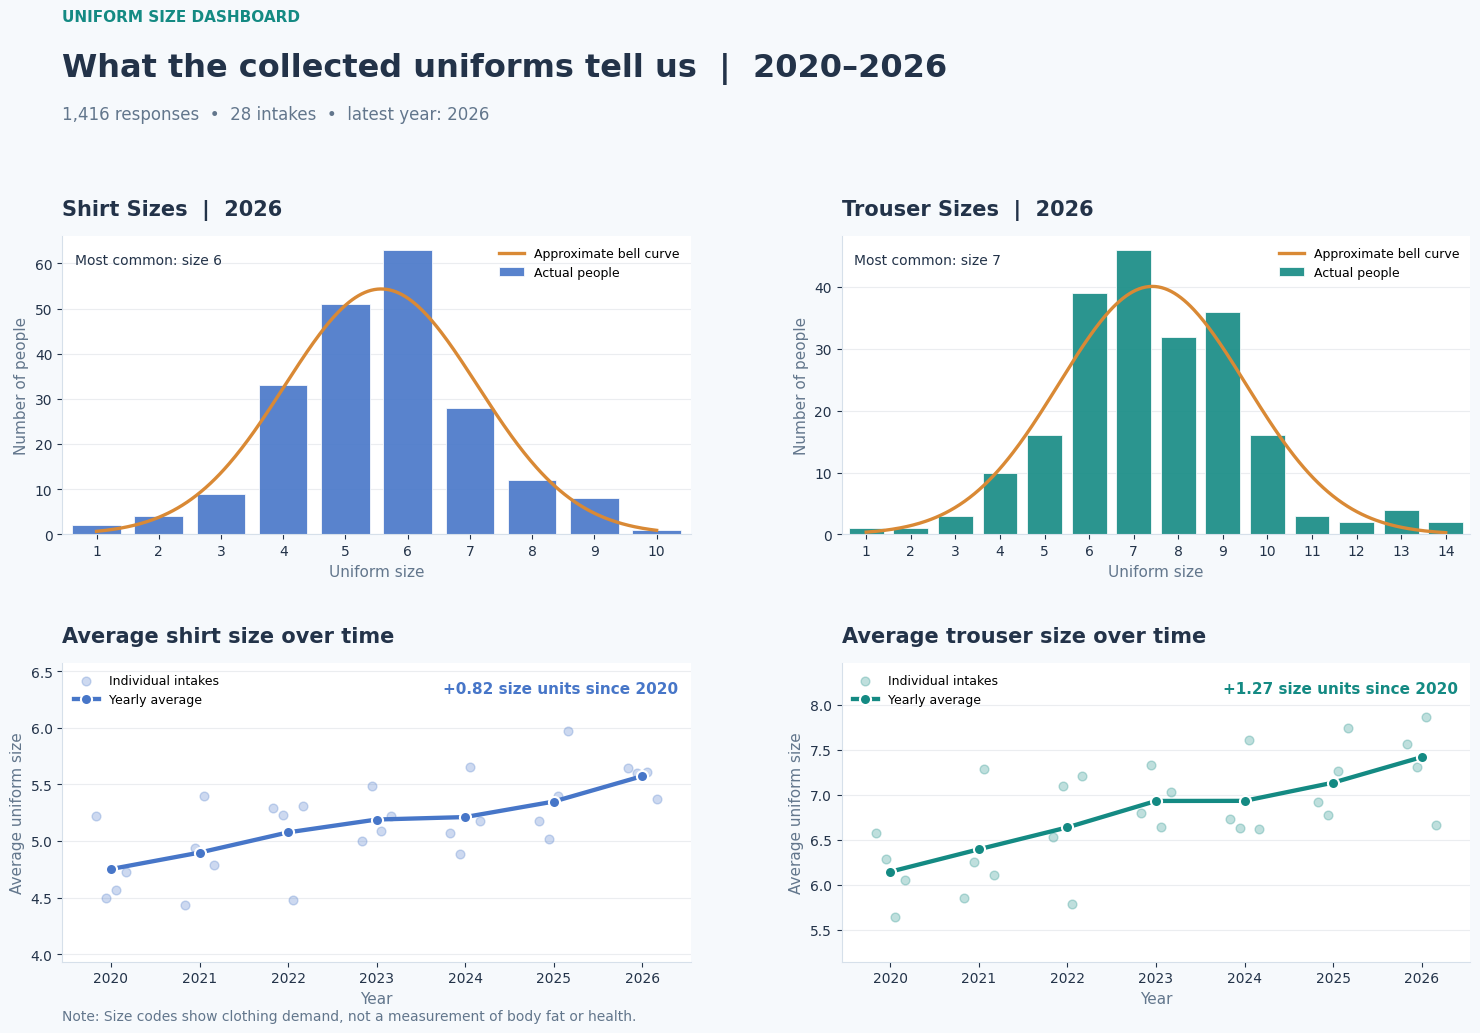

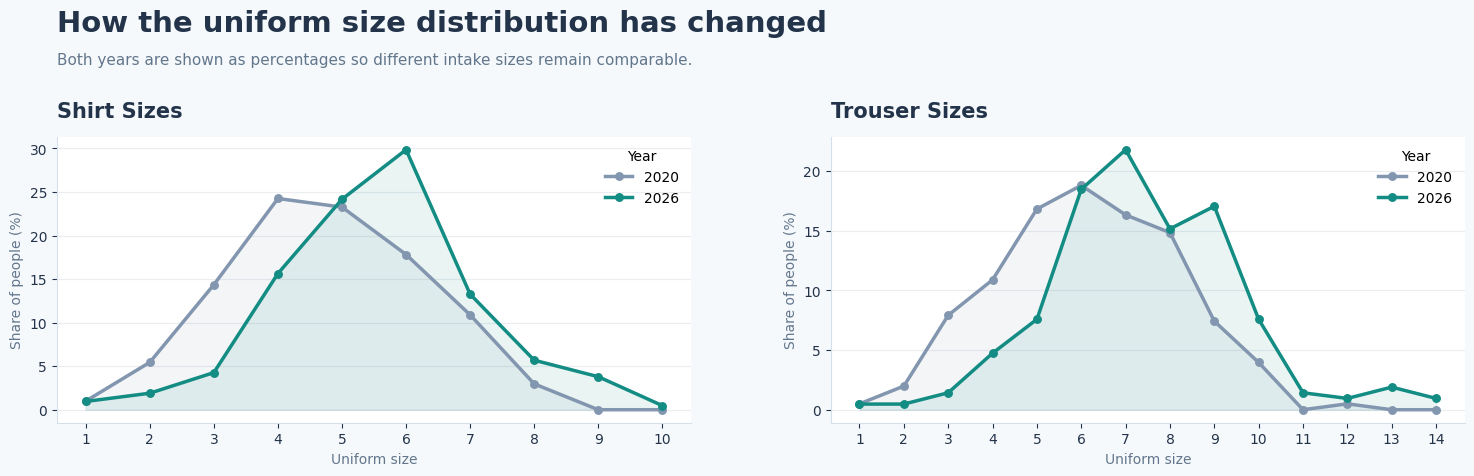

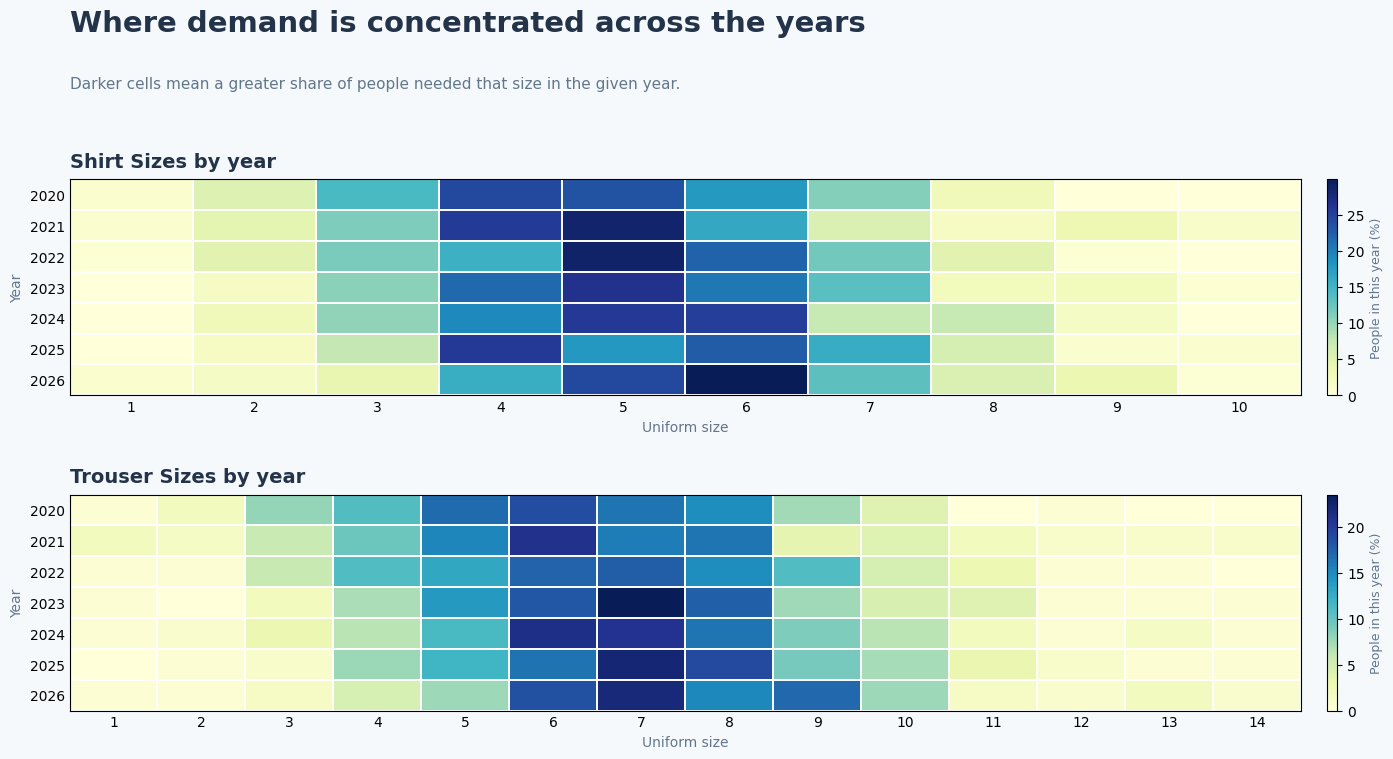

Charts are ready. Copies have been saved in My Drive → Oracle Engine Charts.
To see the exact counts, run Step 6 below.


In [43]:
# @title 5. Show the uniform size charts { display-mode: "form", single-column: true }
# @markdown Click **▶ Run** to see the size distributions, changes over the years, and a colour map showing where demand is concentrated. The charts will also be saved automatically to Google Drive.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display

# Only prepared uniform fields are loaded. No names or response IDs.
# Load the prepared data from the Oracle Engine output folder.
_cleaned_file = Path(
    '/content/drive/MyDrive/OracleEngineSanitizedOutput/Cleaned Data.csv'
)

if not _cleaned_file.is_file():
    raise FileNotFoundError(
        'Cleaned Data.csv was not found. '
        'Please complete Part 1 before viewing the charts.'
    )

_chart_data = pd.read_csv(_cleaned_file, encoding='utf-8-sig')
_required_fields = ['Timestamp', 'Intake', 'No.4 Shirt (Size, Qty)', 'No.4 Trousers (Size, Qty)']
_missing_fields = [c for c in _required_fields if c not in _chart_data.columns]
if _missing_fields:
    raise ValueError('The cleaned file is missing expected uniform fields. Please complete Part 1 again.')

_chart_data['Date'] = pd.to_datetime(_chart_data['Timestamp'], format='%d/%m/%Y %H:%M', errors='coerce')
if _chart_data['Date'].isna().any():
    raise ValueError('Some collection dates could not be read. Please check the cleaned file.')
_chart_data['Year'] = _chart_data['Date'].dt.year
_chart_data['Intake'] = pd.to_numeric(_chart_data['Intake'], errors='raise').astype(int)

for _col, _size_label, _qty_label, _limit in [
    ('No.4 Shirt (Size, Qty)', 'Shirt Size', 'Shirts Issued', 10),
    ('No.4 Trousers (Size, Qty)', 'Trouser Size', 'Trousers Issued', 14),
]:
    _match = _chart_data[_col].astype(str).str.extract(r'(?i)size\s+(\d+)\s*;\s*(\d+)\s*$')
    if _match.isna().any().any():
        raise ValueError('Some shirt/trouser sizes could not be read. Please check Part 1.')
    _chart_data[_size_label] = _match[0].astype(int)
    _chart_data[_qty_label] = _match[1].astype(int)
    if not _chart_data[_size_label].between(1, _limit).all():
        raise ValueError('A shirt/trouser size is outside the supported range.')

_years = sorted(_chart_data['Year'].unique())
_early, _recent = _years[0], _years[-1]
_earliest = _chart_data[_chart_data['Year'] == _early]
_latest = _chart_data[_chart_data['Year'] == _recent]
if not len(_latest):
    raise ValueError('No records found for the latest collection year.')

# Save charts alongside the cleaned data.
_output_folder = _cleaned_file.parent / 'Oracle Engine Charts'
_output_folder.mkdir(parents=True, exist_ok=True)

# Presentation style. All plots use counts or shares directly computed from the CSV.
_BLUE, _TEAL, _ORANGE = '#4776C8', '#148A83', '#D98935'
_OLD, _NEW = '#8396AF', '#138C83'
_INK, _MUTED, _BG = '#233349', '#62768C', '#F6F9FC'

def _pretty(ax):
    ax.set_facecolor('white')
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.spines['left'].set_color('#D6E0EA')
    ax.spines['bottom'].set_color('#D6E0EA')
    ax.tick_params(colors=_INK, labelsize=10)
    ax.yaxis.grid(True, alpha=.12, color='#5F7188')
    ax.set_axisbelow(True)

def _counts(frame, name, high):
    return frame[name].value_counts().reindex(range(1, high+1), fill_value=0).sort_index()

# 1. Main dashboard: actual counts with a fitted bell-shaped reference,
# plus yearly averages and variation among the individual intakes.
_fig, _axs = plt.subplots(2, 2, figsize=(16, 11), facecolor=_BG)
_fig.subplots_adjust(top=.75, bottom=.09, left=.08, right=.96, wspace=.24, hspace=.43)
_fig.text(.08, .945, 'UNIFORM SIZE DASHBOARD', size=11, weight='bold', color=_TEAL)
_fig.text(.08, .895, f'What the collected uniforms tell us  |  {_early}–{_recent}',
          size=23, weight='bold', color=_INK)
_fig.text(.08, .856, f'{len(_chart_data):,} responses  •  {_chart_data["Intake"].nunique()} intakes  •  latest year: {_recent}',
          size=12, color=_MUTED)

for _ax, _name, _high, _color in [
    (_axs[0,0], 'Shirt Size', 10, _BLUE),
    (_axs[0,1], 'Trouser Size', 14, _TEAL),
]:
    _pretty(_ax)
    _ct = _counts(_latest, _name, _high)
    _ax.bar(_ct.index, _ct.values, width=.78, color=_color, alpha=.9,
            edgecolor='white', linewidth=.6, label='Actual people')
    _v = _latest[_name].to_numpy(dtype=float)
    _sd = _v.std(ddof=1) if len(_v) > 1 else 0
    if _sd > .05:
        _xx = np.linspace(1, _high, 360)
        _yy = norm.pdf(_xx, _v.mean(), _sd) * len(_v)
        _ax.plot(_xx, _yy, color=_ORANGE, lw=2.4, label='Approximate bell curve')
    _mode = int(_ct.idxmax())
    _ax.set_title(f'{_name}s  |  {_recent}', loc='left', fontsize=15,
                  fontweight='bold', pad=15, color=_INK)
    _ax.set_xlabel('Uniform size', fontsize=11, color=_MUTED)
    _ax.set_ylabel('Number of people', fontsize=11, color=_MUTED)
    _ax.set_xticks(range(1, _high+1))
    _ax.set_xlim(.45, _high+.55)
    _ax.legend(frameon=False, fontsize=9, loc='upper right')
    _ax.text(.02, .94, f'Most common: size {_mode}', transform=_ax.transAxes,
             color=_INK, fontsize=10, va='top', fontweight='medium')

for _ax, _name, _color in [
    (_axs[1,0], 'Shirt Size', _BLUE),
    (_axs[1,1], 'Trouser Size', _TEAL),
]:
    _pretty(_ax)
    _yr = _chart_data.groupby('Year')[_name].mean().reindex(_years)
    _co = _chart_data.groupby(['Intake', 'Year'])[_name].mean().reset_index()
    _ax.scatter(_co['Year'] + ((_co['Intake'] % 4) - 1.5) * .11,
                _co[_name], s=40, color=_color, alpha=.27, label='Individual intakes')
    _ax.plot(_yr.index, _yr.values, '-o', color=_color, lw=3.1,
             ms=8, markeredgecolor='white', markeredgewidth=1.5,
             label='Yearly average')
    _movement = _yr.iloc[-1] - _yr.iloc[0]
    _ax.set_title(f'Average {_name.lower()} over time', loc='left', fontsize=15,
                  fontweight='bold', pad=15, color=_INK)
    _ax.set_ylabel('Average uniform size', fontsize=11, color=_MUTED)
    _ax.set_xlabel('Year', fontsize=11, color=_MUTED)
    _ax.set_xticks(_years)
    _ax.set_xlim(_early-.55, _recent+.55)
    _ax.set_ylim(min(_co[_name].min(), _yr.min())-.5, max(_co[_name].max(), _yr.max())+.6)
    _ax.legend(frameon=False, fontsize=9, loc='upper left')
    _ax.text(.98, .94, f'{_movement:+.2f} size units since {_early}',
             transform=_ax.transAxes, ha='right', va='top', color=_color, fontsize=11,
             fontweight='bold')

_fig.text(.08, .037, 'Note: Size codes show clothing demand, not a measurement of body fat or health.',
          fontsize=10, color=_MUTED)
_fig.savefig(_output_folder/'01 Uniform Size Dashboard.png', dpi=170, bbox_inches='tight')
plt.show()

# 2. Comparison of historical versus current size distributions as percentages.
_fig2, _ax2 = plt.subplots(1, 2, figsize=(16, 5.2), facecolor=_BG)
_fig2.subplots_adjust(top=.72, bottom=.17, left=.08, right=.96, wspace=.22)
_fig2.suptitle('How the uniform size distribution has changed', x=.08, ha='left',
               y=.965, fontsize=21, fontweight='bold', color=_INK)
_fig2.text(.08, .86, 'Both years are shown as percentages so different intake sizes remain comparable.',
           color=_MUTED, fontsize=11)
for _ax, _name, _high in [(_ax2[0], 'Shirt Size', 10), (_ax2[1], 'Trouser Size', 14)]:
    _pretty(_ax)
    for _frame, _year, _col in [(_earliest, _early, _OLD), (_latest, _recent, _NEW)]:
        _dist = _counts(_frame, _name, _high) / len(_frame) * 100
        _ax.plot(_dist.index, _dist.values, '-o', lw=2.5, ms=5.4, color=_col,
                 label=str(_year))
        _ax.fill_between(_dist.index.to_numpy(), _dist.values, color=_col, alpha=.09)
    _ax.set_title(f'{_name}s', loc='left', fontsize=15, fontweight='bold', color=_INK, pad=14)
    _ax.set_xlabel('Uniform size', color=_MUTED)
    _ax.set_ylabel('Share of people (%)', color=_MUTED)
    _ax.set_xticks(range(1, _high + 1))
    _ax.legend(title='Year', frameon=False, loc='upper right')
_fig2.savefig(_output_folder/'02 Early vs Recent Uniform Sizes.png', dpi=170, bbox_inches='tight')
plt.show()

# 3. Heatmap: one row per year, one column per trouser size.
_fig3, _ax3 = plt.subplots(2, 1, figsize=(16, 8.3), facecolor=_BG)
_fig3.subplots_adjust(top=.76, bottom=.12, left=.11, right=.91, hspace=.46)
_fig3.suptitle('Where demand is concentrated across the years', x=.11, ha='left',
               y=.965, fontsize=21, fontweight='bold', color=_INK)
_fig3.text(.11, .87, 'Darker cells mean a greater share of people needed that size in the given year.',
           color=_MUTED, fontsize=11)
for _ax, _name, _high in [(_ax3[0], 'Shirt Size', 10), (_ax3[1], 'Trouser Size', 14)]:
    _table = pd.crosstab(_chart_data['Year'], _chart_data[_name], normalize='index') * 100
    _table = _table.reindex(index=_years, columns=range(1, _high + 1), fill_value=0)
    _im = _ax.imshow(_table.to_numpy(), aspect='auto', cmap='YlGnBu', vmin=0,
                     vmax=max(1, float(_table.to_numpy().max())))
    _ax.set_facecolor('white')
    _ax.set_yticks(range(len(_years)), labels=_years)
    _ax.set_xticks(range(_high), labels=range(1, _high + 1))
    _ax.set_title(f'{_name}s by year', loc='left', fontsize=14, fontweight='bold', pad=9, color=_INK)
    _ax.set_xlabel('Uniform size', color=_MUTED)
    _ax.set_ylabel('Year', color=_MUTED)
    _ax.tick_params(length=0, labelsize=10)
    _ax.set_xticks(np.arange(-.5, _high, 1), minor=True)
    _ax.set_yticks(np.arange(-.5, len(_years), 1), minor=True)
    _ax.grid(which='minor', color='white', linewidth=1.4)
    _ax.tick_params(which='minor', bottom=False, left=False)
    _cb = _fig3.colorbar(_im, ax=_ax, fraction=.018, pad=.02)
    _cb.set_label('People in this year (%)', color=_MUTED, fontsize=9)
_fig3.savefig(_output_folder/'03 Size Distribution by Year.png', dpi=170, bbox_inches='tight')
plt.show()

print('Charts are ready. Copies have been saved in My Drive → Oracle Engine Charts.')
print('To see the exact counts, run Step 6 below.')

In [47]:

# @title 6. Show the figures behind the charts (optional) { display-mode: "form", single-column: true }
# @markdown Click **▶ Run** to view formatted tables showing yearly collections and uniform quantities.

import pandas as pd
from IPython.display import display

if '_chart_data' not in globals():
    raise RuntimeError('Please run Step 5 first.')


# ---------------------------------------------
# Table formatting
# ---------------------------------------------

def pretty_table(dataframe, title, formats=None):

    styles = [
        {
            'selector': '',
            'props': [
                ('border-collapse', 'collapse'),
                ('font-family', 'Arial, sans-serif'),
                ('font-size', '13px'),
                ('border', '1px solid #B8C9DA')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('caption-side', 'top'),
                ('font-size', '17px'),
                ('font-weight', 'bold'),
                ('text-align', 'left'),
                ('color', '#FFFFFF'),
                ('padding', '12px 4px')
            ]
        },
        {
            'selector': 'th',
            'props': [
                ('background-color', '#DCEAF7'),
                ('color', '#243B53'),
                ('font-weight', 'bold'),
                ('text-align', 'center'),
                ('border', '1px solid #B8C9DA'),
                ('padding', '10px 14px')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('text-align', 'center'),
                ('border', '1px solid #B8C9DA'),
                ('padding', '9px 14px'),
                ('color', '#243B53')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(odd) td',
            'props': [
                ('background-color', '#FFFFFF')
            ]
        },
        {
            'selector': 'tbody tr:nth-child(even) td',
            'props': [
                ('background-color', '#EDF5FC')
            ]
        },
        {
            'selector': 'tbody tr:hover td',
            'props': [
                ('background-color', '#D5E9FA')
            ]
        }
    ]

    # Move Year / Size into the normal table columns.
    # This eliminates the extra empty header row.
    clean_table = (
        dataframe
        .reset_index()
        .rename_axis(columns=None)
    )

    return (
        clean_table.style
        .format(formats or {}, na_rep='-')
        .set_caption(title)
        .set_table_styles(styles)
        .hide(axis='index')
    )

# ---------------------------------------------
# Table 1: Yearly collections
# ---------------------------------------------

_yearly_numbers = _chart_data.groupby('Year').agg(
    People=('Intake', 'size'),
    Intakes=('Intake', 'nunique'),
    Average_Shirt_Size=('Shirt Size', 'mean'),
    Average_Trouser_Size=('Trouser Size', 'mean'),
    Shirts_Issued=('Shirts Issued', 'sum'),
    Trousers_Issued=('Trousers Issued', 'sum'),
).rename(columns={
    'Average_Shirt_Size': 'Average shirt size',
    'Average_Trouser_Size': 'Average trouser size',
    'Shirts_Issued': 'Tops issued',
    'Trousers_Issued': 'Bottoms issued'
})

display(
    pretty_table(
        _yearly_numbers,
        "Annual Uniform Collection Summary",
        {
            'People': '{:,.0f}',
            'Intakes': '{:,.0f}',
            'Average shirt size': '{:.2f}',
            'Average trouser size': '{:.2f}',
            'Tops issued': '{:,.0f}',
            'Bottoms issued': '{:,.0f}'
        }
    )
)


# ---------------------------------------------
# Table 2 & 3: Latest year uniform sizes
# ---------------------------------------------

for _label, _size_col, _qty_col, _max_size in [
    ('Tops', 'Shirt Size', 'Shirts Issued', 10),
    ('Bottoms', 'Trouser Size', 'Trousers Issued', 14),
]:

    _size_data = _latest.groupby(_size_col).agg(
        People=(_size_col, 'size'),
        Pieces=(_qty_col, 'sum')
    ).reindex(
        range(1, _max_size + 1),
        fill_value=0
    )

    _size_data.index.name = 'Size'

    _size_data = _size_data.rename(columns={
        'Pieces': 'Uniform pieces issued'
    })

    display(
        pretty_table(
            _size_data,
            f"{_label} - {_recent} Uniform Requirements",
            {
                'People': '{:,.0f}',
                'Uniform pieces issued': '{:,.0f}'
            }
        )
    )


print(
    "Note: These figures represent historical "
    "uniform collections, not future order recommendations."
)


Year,People,Intakes,Average shirt size,Average trouser size,Tops issued,Bottoms issued
2020,202,4,4.75,6.14,786,786
2021,196,4,4.90,6.39,758,758
2022,209,4,5.08,6.64,804,804
2023,200,4,5.19,6.93,770,770
2024,203,4,5.21,6.93,788,788
2025,195,4,5.35,7.13,754,754
2026,211,4,5.57,7.42,812,812


Size,People,Uniform pieces issued
1,2,8
2,4,16
3,9,34
4,33,124
5,51,196
6,63,240
7,28,110
8,12,48
9,8,32
10,1,4


Size,People,Uniform pieces issued
1,1,4
2,1,4
3,3,12
4,10,36
5,16,64
6,39,146
7,46,172
8,32,128
9,36,138
10,16,64


Note: These figures represent historical uniform collections, not future order recommendations.
